# Notebook 11 – Handling Imbalanced Data

### What is Class Imbalance?


Class Imbalance is a situation in a classification dataset where one class contains significantly more records than another class.

In simple words, when the number of records belonging to different classes is not equally distributed, it is called Class Imbalance


##### Mathematical Concept

Class distribution measures how records are distributed among different classes in a classification dataset.

1. Class Percentage

The class percentage calculates the percentage of records belonging to each class.

Formula:

$$
\text{Class Percentage} =
\frac{\text{Number of Records in Class}}
{\text{Total Number of Records}}
\times 100
$$

Where:

- Number of Records in Class = Number of records belonging to a particular class.
- Total Number of Records = Total records in the dataset.

Example:

Suppose a bank transaction dataset contains 10,000 records.

- Normal Transactions = 9,900
- Fraud Transactions = 100

For Normal Transactions:

$$
\text{Normal Percentage} =
\frac{9900}{10000}\times 100
= 99\%
$$

For Fraud Transactions:

$$
\text{Fraud Percentage} =
\frac{100}{10000}\times 100
= 1\%
$$

Therefore:

- Normal Transactions = 99%
- Fraud Transactions = 1%

2. Imbalance Ratio

The imbalance ratio measures how many times the majority class is larger than the minority class.

Formula:

$$
\text{Imbalance Ratio} =
\frac{\text{Majority Class Count}}
{\text{Minority Class Count}}
$$

Example:

$$
\text{Imbalance Ratio} =
\frac{9900}{100}
= 99:1
$$

Where:

- Majority Class = Normal Transactions (9,900).
- Minority Class = Fraud Transactions (100).

Interpretation:

A 99:1 imbalance ratio means that for every 1 fraud transaction, there are 99 normal transactions.

Conclusion:

The dataset is highly imbalanced because Normal Transactions represent 99% of the records, whereas Fraud Transactions represent only 1%.


Why is Class Imbalance a Problem?

Class imbalance can affect machine learning models in several ways:
1. Biased Predictions: The model may learn to predict the majority class more frequently.
2. Poor Minority Class Detection: The model may fail to identify important minority-class records.
3. Misleading Accuracy: A model can achieve high accuracy but still perform poorly on the minority class.
4. Poor Fraud Detection: The model may fail to identify fraudulent transactions.

Class Distribution:
Transaction_Type
Normal    9900
Fraud      100
Name: count, dtype: int64

Class Percentage:
Transaction_Type
Normal    99.0
Fraud      1.0
Name: proportion, dtype: float64

Imbalance Ratio: 99.0


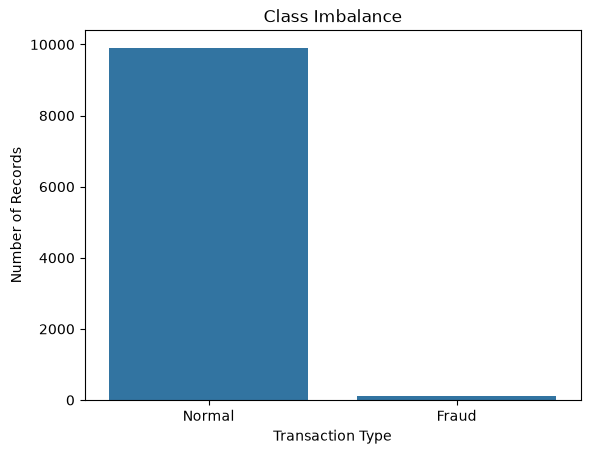

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create dataset
data = {
    'Transaction_ID': range(1, 10001),
    'Transaction_Type': ['Normal'] * 9900 + ['Fraud'] * 100
}

df = pd.DataFrame(data)

# Count each class
class_counts = df['Transaction_Type'].value_counts()

print("Class Distribution:")
print(class_counts)

# Calculate class percentages
class_percentage = df['Transaction_Type'].value_counts(
    normalize=True
) * 100

print("\nClass Percentage:")
print(class_percentage)

# Calculate imbalance ratio
majority = class_counts.max()
minority = class_counts.min()

imbalance_ratio = majority / minority

print("\nImbalance Ratio:", imbalance_ratio)

# Visualize class distribution
sns.countplot(data=df, x='Transaction_Type')

plt.title('Class Imbalance')
plt.xlabel('Transaction Type')
plt.ylabel('Number of Records')
plt.show()

How to Handle Class Imbalance?

Common techniques include:

- Random Undersampling: Reduce majority-class records.
- Random Oversampling: Increase minority-class records.
- SMOTE: Generate synthetic minority-class samples.
- Class Weights: Give more importance to minority-class records.

### Balanced vs Imbalanced Dataset


A Balanced Dataset is a dataset in which the number of records belonging to each target class is approximately equal.

In Machine Learning, balanced datasets are commonly used for classification problems.


##### Mathematical Concept

Class percentage tells us how much each class contributes to the total dataset.

The formula is:

$$
\text{Class Percentage} =
\frac{\text{Number of Records in Class}}
{\text{Total Number of Records}} \times 100
$$

##### For Normal Transactions

$$
= \frac{500}{1000} \times 100
$$

$$
= 50\%
$$

##### For Fraud Transactions

$$
= \frac{500}{1000} \times 100
$$

$$
= 50\%
$$

##### Result

- Normal Transactions = 50%
- Fraud Transactions = 50%

Both classes have equal representation.

Therefore, this dataset is called a Balanced Dataset.


Class Distribution:
Transaction_Type
Normal    9900
Fraud      100
Name: count, dtype: int64

Class Percentage:
Transaction_Type
Normal    99.0
Fraud      1.0
Name: proportion, dtype: float64

Imbalance Ratio: 99.0


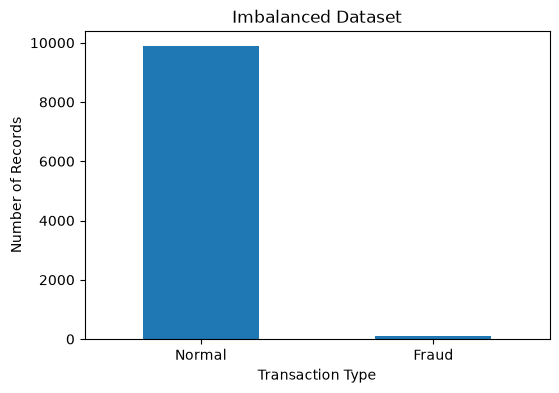

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Create an imbalanced dataset
data = {
    'Transaction_Type': ['Normal'] * 9900 + ['Fraud'] * 100
}

df = pd.DataFrame(data)

# Calculate class counts
class_counts = df['Transaction_Type'].value_counts()

print("Class Distribution:")
print(class_counts)

# Calculate class percentages
class_percentage = df['Transaction_Type'].value_counts(normalize=True) * 100

print("\nClass Percentage:")
print(class_percentage)

# Calculate imbalance ratio
imbalance_ratio = class_counts.max() / class_counts.min()

print("\nImbalance Ratio:", imbalance_ratio)

# Visualize class distribution
class_counts.plot(kind='bar', figsize=(6, 4))

plt.title("Imbalanced Dataset")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.show()

In [ ]:
Difference Between Balanced and Imbalanced Datasets:

Balanced Dataset	                                Imbalanced Dataset

Classes have approximately equal records.	     Classes have significantly different records.
Each class gets similar representation.	         Some classes have much higher representation.
Less risk of majority-class prediction bias.	Model may favor the majority class.
Usually easier to evaluate using accuracy.	    Accuracy alone can be misleading.
Resampling may not be necessary.	            Resampling or class weighting may be useful.

How to Handle Imbalanced Datasets

Common techniques includes

1. Random Oversampling

Increases the number of minority-class records by duplicating existing samples.

2. Random Undersampling

Reduces the number of majority-class records.

3. SMOTE

Generates synthetic minority-class samples using existing minority-class observations.

4. Class Weighting

Assigns higher penalties to mistakes involving the minority class during model training.


Important: Apply resampling only to the training dataset, after splitting the data into training and testing sets. Do not balance the test dataset artificially.

### Why Class Imbalance is a Problem


Class imbalance is a problem in Machine Learning when one target class contains significantly more records than another target class.

When a dataset is imbalanced, a Machine Learning model may learn to predict the majority class more frequently than the minority class.

As a result, the model may fail to identify important minority-class cases.

Why Does Class Imbalance Create a Problem?

Problem 1: Model Bias Towards Majority Class

When a dataset contains more majority-class records, the model may become biased towards predicting the majority class.

For example:

- Normal transactions = 9,900
- Fraud transactions = 100
Suppose the model predicts every transaction as Normal.

It correctly predicts all 9,900 Normal transactions but misses all 100 Fraud transactions.

Therefore, the model fails to detect fraud.

Problem 2: Misleading Accuracy

Accuracy measures the percentage of correct predictions made by a model.


##### Mathematical Concept

Accuracy measures how many predictions are correct out of all predictions.

The formula is:

$$
\text{Accuracy} =
\frac{\text{Number of Correct Predictions}}
{\text{Total Number of Predictions}} \times 100
$$

For example:

$$
\text{Accuracy} =
\frac{9900}{10000} \times 100
$$

$$
= 99\%
$$

Therefore, the model achieves 99% accuracy.


But what is the problem?

Although the model achieves 99% accuracy, it does not identify even one Fraud transaction.

This means high accuracy does not always indicate a good Machine Learning model.

In [3]:
# Actual class distribution
total_records = 10000

normal_records = 9900
fraud_records = 100

# Model predicts every transaction as Normal
correct_predictions = 9900

# Calculate accuracy
accuracy = (correct_predictions / total_records) * 100

print("Total Records:", total_records)
print("Correct Predictions:", correct_predictions)
print("Model Accuracy:", accuracy, "%")
print("Fraud Transactions Detected: 0")

Total Records: 10000
Correct Predictions: 9900
Model Accuracy: 99.0 %
Fraud Transactions Detected: 0


Problem 3: Poor Minority Class Prediction

The minority class contains fewer training examples.

For example:

- Normal transactions = 9,900
- Fraud transactions = 100
  
The model has many examples of Normal transactions but very few examples of Fraud transactions.

As a result, it may struggle to learn the patterns associated with fraudulent transactions.

Problem 4: Low Recall

Recall measures how many actual positive cases are correctly identified by the model.


##### Recall

$$
\text{Recall} =
\frac{TP}{TP+FN}
$$

Where:

- TP = True Positives
- FN = False Negatives

For fraud detection:

- TP = Correctly identified fraud transactions.
- FN = Fraud transactions incorrectly predicted as Normal.


Suppose:

- Actual Fraud transactions = 100
- Correctly detected Fraud transactions = 20
- Missed Fraud transactions = 80
Then:
\[
\text{Recall} = \frac{20}{20+80}
\]

\[
= 20\%
\]

The model detects only 20% of actual fraudulent transactions.

This is a serious problem in fraud detection.

### Undersampling


Undersampling is a technique used to handle an imbalanced dataset by reducing the number of records in the majority class to make the class distribution more balanced.

In simple words, undersampling removes some records from the majority class so that both majority and minority classes have a more equal number of records.


##### Mathematical Concept

Undersampling reduces the number of majority-class records while keeping the minority-class records unchanged.

##### Before Undersampling

Suppose:

$$
N_{\text{majority}} = 9900
$$

$$
N_{\text{minority}} = 100
$$

##### After Undersampling

$$
N_{\text{majority}} = 100
$$

$$
N_{\text{minority}} = 100
$$

##### Total Records After Undersampling

$$
N_{\text{total}} = 100 + 100
$$

$$
= 200
$$

##### Class Percentage

Class percentage can be calculated using:

$$
\text{Class Percentage} =
\frac{\text{Number of Records in Class}}
{\text{Total Records}} \times 100
$$

**For Normal Transactions:**

$$
= \frac{100}{200} \times 100
$$

$$
= 50\%
$$

**For Fraud Transactions:**

$$
= \frac{100}{200} \times 100
$$

$$
= 50\%
$$

##### Final Result

- Normal transactions = 50%
- Fraud transactions = 50%

The dataset is now balanced after applying Undersampling.


Before Undersampling:
Transaction_Type
Normal    9900
Fraud      100
Name: count, dtype: int64

After Undersampling:
Transaction_Type
Fraud     100
Normal    100
Name: count, dtype: int64

Total Records After Undersampling: 200

Class Percentages:
Transaction_Type
Fraud     50.0
Normal    50.0
Name: proportion, dtype: float64

Imbalance Ratio: 1.0


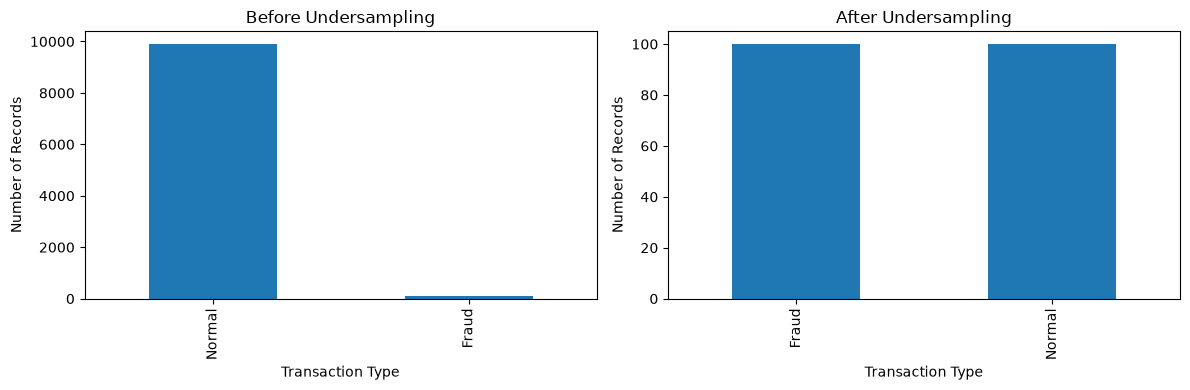

In [6]:

import pandas as pd
import matplotlib.pyplot as plt
from imblearn.under_sampling import RandomUnderSampler

# Step 1: Create an imbalanced dataset
data = {
    'Transaction_Amount': [100] * 9900 + [5000] * 100,
    'Transaction_Type': ['Normal'] * 9900 + ['Fraud'] * 100
}

df = pd.DataFrame(data)

# Step 2: Separate features and target
X = df[['Transaction_Amount']]
y = df['Transaction_Type']

# Step 3: Display original class distribution
print("Before Undersampling:")
print(y.value_counts())

# Step 4: Apply Random Undersampling
rus = RandomUnderSampler(random_state=42)
X_under, y_under = rus.fit_resample(X, y)

# Step 5: Display new class distribution
print("\nAfter Undersampling:")
print(y_under.value_counts())

# Step 6: Calculate total records
total_records = len(y_under)

print("\nTotal Records After Undersampling:", total_records)

# Step 7: Calculate class percentages
class_percentage = y_under.value_counts(normalize=True) * 100

print("\nClass Percentages:")
print(class_percentage)

# Step 8: Calculate imbalance ratio
class_counts = y_under.value_counts()
imbalance_ratio = class_counts.max() / class_counts.min()

print("\nImbalance Ratio:", imbalance_ratio)

# Step 9: Visualize before and after undersampling
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

y.value_counts().plot(kind='bar', ax=axes[0])
axes[0].set_title("Before Undersampling")
axes[0].set_xlabel("Transaction Type")
axes[0].set_ylabel("Number of Records")

y_under.value_counts().plot(kind='bar', ax=axes[1])
axes[1].set_title("After Undersampling")
axes[1].set_xlabel("Transaction Type")
axes[1].set_ylabel("Number of Records")

plt.tight_layout()
plt.show()


Advantages of Undersampling:

1. Reduces dataset size.
2. Decreases model training time.
3. Reduces majority-class dominance.
4. Creates a more balanced class distribution.
5. Can improve minority-class prediction performance.
   
Disadvantages of Undersampling:

1. Removes useful majority-class information.
2. May cause information loss.
3. Can reduce model performance if important records are removed.
4. Random selection may remove important patterns.
5. May cause poor generalization if too many records are discarded.

### Oversampling


Oversampling is a technique used to handle an imbalanced dataset by increasing the number of records in the minority class to make the class distribution more balanced.

In simple words, oversampling adds more minority-class records while keeping the majority-class records unchanged.


##### Mathematical Concept

Oversampling increases the number of minority-class records while keeping the majority-class records unchanged.

##### Before Oversampling

Suppose:

$$
N_{\text{majority}} = 9900
$$

$$
N_{\text{minority}} = 100
$$

##### After Oversampling

$$
N_{\text{majority}} = 9900
$$

$$
N_{\text{minority}} = 9900
$$

##### Total Records After Oversampling

$$
N_{\text{total}} = 9900 + 9900
$$

$$
= 19800
$$

##### Class Percentage

Class percentage can be calculated using:

$$
\text{Class Percentage} =
\frac{\text{Number of Records in Class}}
{\text{Total Records}} \times 100
$$

For Normal Transactions:

$$
= \frac{9900}{19800} \times 100
$$

$$
= 50\%
$$

For Fraud Transactions:

$$
= \frac{9900}{19800} \times 100
$$

$$
= 50\%
$$

Final Result

- Normal transactions = 50%
- Fraud transactions = 50%

The dataset is now balanced after applying Oversampling.


Types of Oversampling:

1. Random Oversampling
   
Random Oversampling randomly duplicates existing minority-class records to increase their number.

Example:

- Before: Normal = 9,900
- Before: Fraud = 100
- After: Normal = 9,900
- After: Fraud = 9,900
  
2. SMOTE (Synthetic Minority Oversampling Technique)
   
SMOTE generates new synthetic minority-class records using existing minority-class observations and their nearest neighbors.

Before Oversampling:
Transaction_Type
Normal    9900
Fraud      100
Name: count, dtype: int64

After Oversampling:
Transaction_Type
Normal    9900
Fraud     9900
Name: count, dtype: int64

Total Records After Oversampling: 19800

Class Percentages:
Transaction_Type
Normal    50.0
Fraud     50.0
Name: proportion, dtype: float64

Imbalance Ratio: 1.0


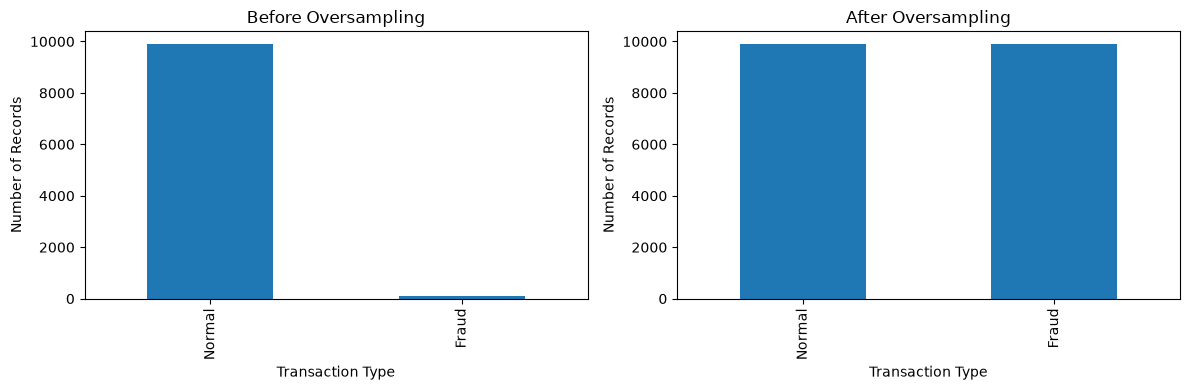

In [7]:

import pandas as pd
import matplotlib.pyplot as plt
from imblearn.over_sampling import RandomOverSampler

# Step 1: Create an imbalanced dataset
data = {
    'Transaction_Amount': [100] * 9900 + [5000] * 100,
    'Transaction_Type': ['Normal'] * 9900 + ['Fraud'] * 100
}

df = pd.DataFrame(data)

# Step 2: Separate features and target
X = df[['Transaction_Amount']]
y = df['Transaction_Type']

# Step 3: Display original class distribution
print("Before Oversampling:")
print(y.value_counts())

# Step 4: Apply Random Oversampling
ros = RandomOverSampler(random_state=42)
X_over, y_over = ros.fit_resample(X, y)

# Step 5: Display new class distribution
print("\nAfter Oversampling:")
print(y_over.value_counts())

# Step 6: Calculate total records
total_records = len(y_over)

print("\nTotal Records After Oversampling:", total_records)

# Step 7: Calculate class percentages
class_percentage = y_over.value_counts(normalize=True) * 100

print("\nClass Percentages:")
print(class_percentage)

# Step 8: Calculate imbalance ratio
class_counts = y_over.value_counts()
imbalance_ratio = class_counts.max() / class_counts.min()

print("\nImbalance Ratio:", imbalance_ratio)

# Step 9: Visualize before and after oversampling
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

y.value_counts().plot(kind='bar', ax=axes[0])
axes[0].set_title("Before Oversampling")
axes[0].set_xlabel("Transaction Type")
axes[0].set_ylabel("Number of Records")

y_over.value_counts().plot(kind='bar', ax=axes[1])
axes[1].set_title("After Oversampling")
axes[1].set_xlabel("Transaction Type")
axes[1].set_ylabel("Number of Records")

plt.tight_layout()
plt.show()


Advantages of Oversampling:

1. Retains all majority-class records.
2. Increases minority-class representation.
3. Reduces majority-class prediction bias.
4. Can improve minority-class Recall.
5. Does not discard existing majority-class information.
   
Disadvantages of Oversampling:

1. Increases dataset size.
2. Increases model training time.
3. Random Oversampling can cause overfitting due to duplicate records.
4. May increase memory usage.
5. Does not guarantee better model performance.

### Random Oversampling


Random Oversampling is a technique used to handle an imbalanced dataset by randomly duplicating existing records from the minority class to increase its size.

In simple words, Random Oversampling copies minority-class records until the minority class reaches the required number of records.


##### Mathematical Concept

Random Oversampling increases minority-class records by duplicating existing samples.

##### Before Oversampling

Suppose:

$$
N_{\text{majority}} = 9900
$$

$$
N_{\text{minority}} = 100
$$

Additional Minority-Class Records Required

$$
N_{\text{additional}} =
N_{\text{majority}} - N_{\text{minority}}
$$

$$
= 9900 - 100
$$

$$
= 9800
$$

##### After Oversampling

$$
N_{\text{minority}} = 100 + 9800
$$

$$
= 9900
$$

 Total Records

$$
N_{\text{total}} = 9900 + 9900
$$

$$
= 19800
$$

###### Class Percentage

Class percentage can be calculated using:

$$
\text{Class Percentage} =
\frac{\text{Number of Records in Class}}
{\text{Total Records}} \times 100
$$

For Normal Transactions:

$$
= \frac{9900}{19800} \times 100
$$

$$
= 50\%
$$

**For Fraud Transactions:**

$$
= \frac{9900}{19800} \times 100
$$

$$
= 50\%
$$

Final Result

- Normal transactions = 50%
- Fraud transactions = 50%

Both classes have equal representation.

Therefore, the dataset is balanced after applying Random Oversampling.


Before Random Oversampling:
Transaction_Type
Normal    9900
Fraud      100
Name: count, dtype: int64

After Random Oversampling:
Transaction_Type
Normal    9900
Fraud     9900
Name: count, dtype: int64

Total Records: 19800

Class Percentages:
Transaction_Type
Normal    50.0
Fraud     50.0
Name: proportion, dtype: float64

Additional Records: 9800


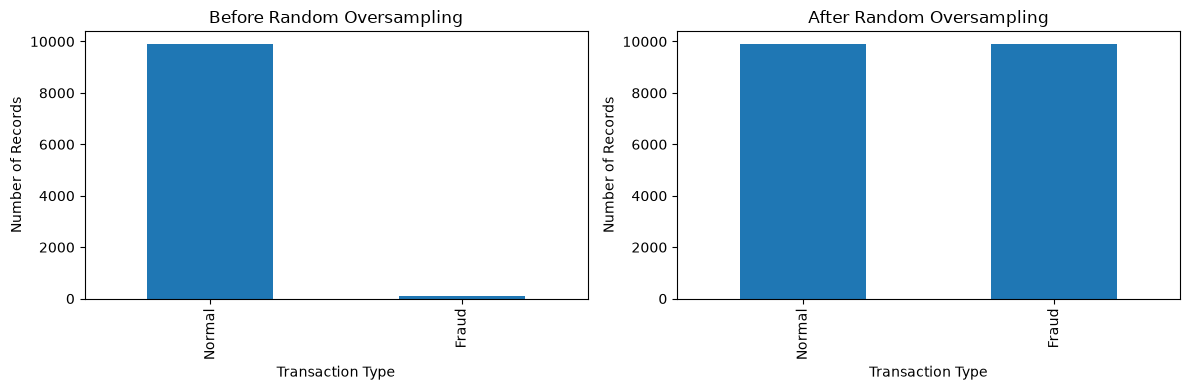

In [8]:

import pandas as pd
import matplotlib.pyplot as plt
from imblearn.over_sampling import RandomOverSampler

# Step 1: Create an imbalanced dataset
data = {
    'Transaction_Amount': [100] * 9900 + [5000] * 100,
    'Transaction_Type': ['Normal'] * 9900 + ['Fraud'] * 100
}

df = pd.DataFrame(data)

# Step 2: Separate features and target
X = df[['Transaction_Amount']]
y = df['Transaction_Type']

# Step 3: Display original class distribution
print("Before Random Oversampling:")
print(y.value_counts())

# Step 4: Apply Random Oversampling
ros = RandomOverSampler(random_state=42)

X_resampled, y_resampled = ros.fit_resample(X, y)

# Step 5: Display new class distribution
print("\nAfter Random Oversampling:")
print(y_resampled.value_counts())

# Step 6: Calculate total records
total_records = len(y_resampled)

print("\nTotal Records:", total_records)

# Step 7: Calculate class percentages
class_percentage = y_resampled.value_counts(normalize=True) * 100

print("\nClass Percentages:")
print(class_percentage)

# Step 8: Calculate additional records
additional_records = len(y_resampled) - len(y)

print("\nAdditional Records:", additional_records)

# Step 9: Visualize before and after
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

y.value_counts().plot(kind='bar', ax=axes[0])
axes[0].set_title("Before Random Oversampling")
axes[0].set_xlabel("Transaction Type")
axes[0].set_ylabel("Number of Records")

y_resampled.value_counts().plot(kind='bar', ax=axes[1])
axes[1].set_title("After Random Oversampling")
axes[1].set_xlabel("Transaction Type")
axes[1].set_ylabel("Number of Records")

plt.tight_layout()
plt.show()


Advantages of Random Oversampling:

1. Simple and easy to implement.
2. Retains all original majority-class records.
3. Increases minority-class representation.
4. Reduces majority-class dominance.
5. Can improve minority-class Recall.
   
Disadvantages of Random Oversampling:

1. Creates duplicate records.
2. May cause overfitting.
3. Increases dataset size.
4. Requires more memory.
5. May increase model training time.

### Random Undersampling


Random Undersampling is a technique used to handle an imbalanced dataset by randomly removing records from the majority class to make the class distribution balanced.

In simple words, it randomly selects and removes some majority-class records while keeping the minority-class records unchanged.


##### Mathematical Concept – Random Undersampling

Random Undersampling reduces the number of majority-class records while keeping minority-class records unchanged.

##### 1. Initial Class Distribution

Suppose a fraud detection dataset contains:

- Normal transactions (Majority Class) = 9,900
- Fraud transactions (Minority Class) = 100

$$
N_{\text{majority}} = 9900
$$

$$
N_{\text{minority}} = 100
$$

##### 2. Calculate the Number of Records to Remove

The number of majority-class records to remove is:

$$
N_{\text{removed}} =
N_{\text{majority}} - N_{\text{minority}}
$$

Substitute the values:

$$
N_{\text{removed}} = 9900 - 100
$$

$$
N_{\text{removed}} = 9800
$$

Therefore, 9,800 Normal transaction records are randomly removed.

##### 3. Class Distribution After Undersampling

The remaining majority-class records are:

$$
N_{\text{majority after}} =
9900 - 9800
$$

$$
N_{\text{majority after}} = 100
$$

The minority-class records remain unchanged:

$$
N_{\text{minority after}} = 100
$$

##### 4. Calculate Total Records

$$
N_{\text{total}} =
N_{\text{majority after}} +
N_{\text{minority after}}
$$

$$
N_{\text{total}} = 100 + 100
$$

$$
N_{\text{total}} = 200
$$

##### 5. Calculate Class Percentage

For Normal Transactions:

$$
\text{Normal Percentage} =
\frac{100}{200} \times 100
$$

$$
= 50\%
$$

For Fraud Transactions:

$$
\text{Fraud Percentage} =
\frac{100}{200} \times 100
$$

$$
= 50\%
$$

##### 6. Final Result

After Random Undersampling:

| Class | Before | After |
|---|---:|---:|
| Normal | 9,900 | 100 |
| Fraud | 100 | 100 |
| **Total** | **10,000** | **200** |

Both classes now have equal representation.

**Conclusion:** Random Undersampling balances the dataset by randomly removing majority-class records while retaining all minority-class records. However, it removes 9,800 records in this example, which may result in the loss of useful information.


Before Random Undersampling:
Transaction_Type
Normal    9900
Fraud      100
Name: count, dtype: int64

After Random Undersampling:
Transaction_Type
Fraud     100
Normal    100
Name: count, dtype: int64

Removed Records: 9800
Total Records After Undersampling: 200

Class Percentages:
Transaction_Type
Fraud     50.0
Normal    50.0
Name: proportion, dtype: float64

Imbalance Ratio: 1.0


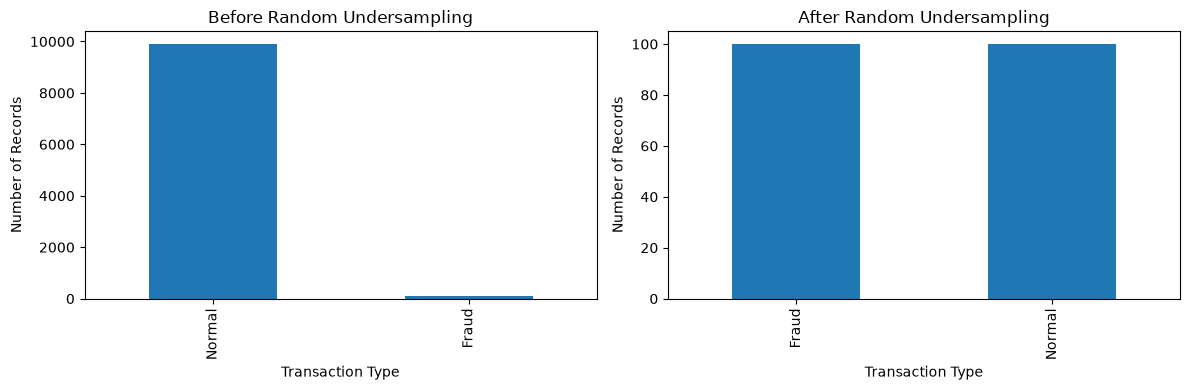

In [9]:

import pandas as pd
import matplotlib.pyplot as plt
from imblearn.under_sampling import RandomUnderSampler

# Step 1: Create an imbalanced dataset
data = {
    'Transaction_Amount': [100] * 9900 + [5000] * 100,
    'Transaction_Type': ['Normal'] * 9900 + ['Fraud'] * 100
}

df = pd.DataFrame(data)

# Step 2: Separate features and target
X = df[['Transaction_Amount']]
y = df['Transaction_Type']

# Step 3: Display original distribution
print("Before Random Undersampling:")
print(y.value_counts())

# Step 4: Apply Random Undersampling
rus = RandomUnderSampler(random_state=42)

X_under, y_under = rus.fit_resample(X, y)

# Step 5: Display new distribution
print("\nAfter Random Undersampling:")
print(y_under.value_counts())

# Step 6: Calculate removed records
removed_records = len(y) - len(y_under)

print("\nRemoved Records:", removed_records)

# Step 7: Calculate total records
total_records = len(y_under)

print("Total Records After Undersampling:", total_records)

# Step 8: Calculate class percentages
class_percentage = y_under.value_counts(normalize=True) * 100

print("\nClass Percentages:")
print(class_percentage)

# Step 9: Calculate imbalance ratio
class_counts = y_under.value_counts()

imbalance_ratio = class_counts.max() / class_counts.min()

print("\nImbalance Ratio:", imbalance_ratio)

# Step 10: Visualize before and after
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

y.value_counts().plot(kind='bar', ax=axes[0])
axes[0].set_title("Before Random Undersampling")
axes[0].set_xlabel("Transaction Type")
axes[0].set_ylabel("Number of Records")

y_under.value_counts().plot(kind='bar', ax=axes[1])
axes[1].set_title("After Random Undersampling")
axes[1].set_xlabel("Transaction Type")
axes[1].set_ylabel("Number of Records")

plt.tight_layout()
plt.show()


Advantages:

1. Easy to implement.
2. Reduces dataset size.
3. Decreases model training time.
4. Reduces majority-class dominance.
5. Can improve minority-class prediction
   
Disadvantages:

1. Removes useful majority-class information.
2. May lose important patterns.
3. Random selection may remove valuable records.
4. Can reduce model generalization.
5. May negatively affect model performance

### SMOTE

SMOTE stands for Synthetic Minority Over-sampling Technique.

SMOTE is a data balancing technique used in Machine Learning to handle an imbalanced dataset.

It works by generating new synthetic records for the minority class instead of simply copying existing records.

For example, in a fraud detection dataset:
- Normal transactions = 9,900 (Majority Class)
- Fraud transactions = 100 (Minority Class)
SMOTE generates new synthetic Fraud records to balance the dataset.

##### Mathematical Concept

SMOTE generates synthetic minority-class samples using the following formula:

$$
X_} = X_i + \lambda (X_ - X_i)
$$

Where:
- X_DIL0} = Newly generated synthetic sample.
- \(X_i\) = Existing minority-class sample.
- X_DIL1 = One of its nearest minority-class neighbors.
- \(\lambda\) = Random value between 0 and 1.
Example
Suppose two minority-class records have these values:

$$
X_i = 20
$$

$$
X_ = 40
$$

Assume:

$$
\lambda = 0.5
$$

Substitute the values:



$$
=20+0.5(20)
$$

$$
=20+10
$$

$$
=30
$$
New synthetic value = 30
SMOTE generates a new sample between the two existing minority-class samples.

How Does SMOTE Work


1. Identify the minority class.
2. Select a minority-class sample.
3. Find its nearest minority-class neighbors.
4. Select one neighbor randomly.
5. Generate a synthetic sample between the selected sample and its neighbor.
6. Repeat until the required class balance is achieved.

Before SMOTE:
Class
0    9852
1     148
Name: count, dtype: int64

After SMOTE:
Class
0    9852
1    9852
Name: count, dtype: int64

Total Records Before: 10000
Total Records After: 19704


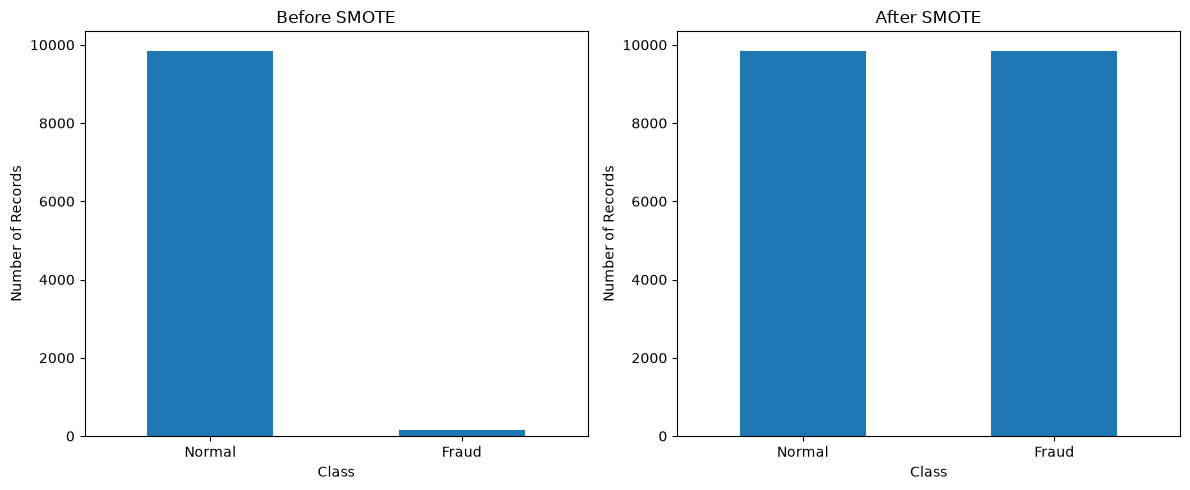

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from imblearn.over_sampling import SMOTE

# Create an imbalanced dataset
X, y = make_classification(
    n_samples=10000,
    n_features=5,
    n_informative=3,
    n_redundant=0,
    n_classes=2,
    weights=[0.99, 0.01],
    random_state=42
)

# Convert into DataFrame
df = pd.DataFrame(
    X,
    columns=["Amount", "Income", "Age", "Balance", "Score"]
)

df["Class"] = y

# Display class distribution before SMOTE
print("Before SMOTE:")
print(df["Class"].value_counts())

# Separate features and target
X = df.drop("Class", axis=1)
y = df["Class"]

# Apply SMOTE
smote = SMOTE(random_state=42)

X_resampled, y_resampled = smote.fit_resample(X, y)

# Display class distribution after SMOTE
print("\nAfter SMOTE:")
print(pd.Series(y_resampled).value_counts())

# Calculate total records
print("\nTotal Records Before:", len(y))
print("Total Records After:", len(y_resampled))

# Visualize class distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

pd.Series(y).value_counts().sort_index().plot(
    kind="bar", ax=axes[0]
)
axes[0].set_title("Before SMOTE")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Number of Records")
axes[0].set_xticklabels(["Normal", "Fraud"], rotation=0)

pd.Series(y_resampled).value_counts().sort_index().plot(
    kind="bar", ax=axes[1]
)
axes[1].set_title("After SMOTE")
axes[1].set_xlabel("Class")
axes[1].set_ylabel("Number of Records")
axes[1].set_xticklabels(["Normal", "Fraud"], rotation=0)

plt.tight_layout()
plt.show()

Advantages of SMOTE:

- Generates new minority-class samples.
- Helps balance imbalanced datasets.
- Does not remove majority-class records.
- Can improve minority-class detection.
- Useful in fraud detection and medical diagnosis.

Disadvantages of SMOTE

- May generate noisy or unrealistic samples.
- Can create overlapping samples between classes.
- Increases dataset size.
- May increase training time.
- Can perform poorly when minority-class data contains many outliers.

### Borderline-SMOTE


Borderline-SMOTE is an advanced version of SMOTE used to handle imbalanced datasets in Machine Learning.

It generates synthetic minority-class samples mainly near the decision boundary, where minority-class records are close to majority-class records.

In simple words:

- Regular SMOTE generates synthetic samples across the minority-class region.
- Borderline-SMOTE focuses on minority-class samples that are difficult to classify because they are surrounded by majority-class samples.

Why Do We Use Borderline-SMOTE?

Consider two types of minority-class records:

1. Safe samples: Minority-class records surrounded mostly by other minority-class records.
2. Borderline samples: Minority-class records surrounded by both minority-class and majority-class records.
   
Borderline samples are more difficult for a model to classify correctly.

Borderline-SMOTE concentrates on these difficult samples to improve learning near the class boundary.


##### Mathematical Concept

Suppose a minority-class observation is represented by:

$$
X_i
$$

A nearby minority-class observation is represented by:

$$
X_{\text{neighbor}}
$$

Borderline-SMOTE generates a synthetic sample using:

$$
X_{\text{new}} = X_i + \lambda(X_{\text{neighbor}} - X_i)
$$

**Where:**

- $X_{\text{new}}$ = Newly generated synthetic sample.
- $X_i$ = Original minority-class sample.
- $X_{\text{neighbor}}$ = Nearest minority-class neighbor.
- $\lambda$ = Random number between 0 and 1.

 Example

Suppose:

$$
X_i = 20
$$

$$
X_{\text{neighbor}} = 30
$$

$$
\lambda = 0.5
$$

**Step 1: Substitute the values**

$$
X_{\text{new}} = 20 + 0.5(30 - 20)
$$

**Step 2: Calculate the difference**

$$
X_{\text{new}} = 20 + 0.5(10)
$$

**Step 3: Multiply**

$$
X_{\text{new}} = 20 + 5
$$

**Final Answer:**

$$
\boxed{X_{\text{new}} = 25}
$$

The newly generated synthetic sample has a value of 25.


Types of Borderline-SMOTE

There are two main variants:

Borderline-SMOTE-1

- Identifies minority samples near the decision boundary.
- Generates synthetic samples using nearby minority-class observations.
  
Borderline-SMOTE-2

- Identifies minority samples near the decision boundary.
- Can use both minority-class and majority-class neighbors when generating synthetic samples.
- Requires additional care because generated samples may overlap with the majority class.

Original Dataset Distribution:
Counter({np.int64(0): 895, np.int64(1): 105})

Before Borderline-SMOTE:
Counter({np.int64(0): 716, np.int64(1): 84})

After Borderline-SMOTE:
Counter({np.int64(0): 716, np.int64(1): 716})

Mathematical Calculation:
X_new = X_i + lambda * (X_neighbor - X_i)
X_new = 20 + 0.5 * (30 - 20)
X_new = 25.0


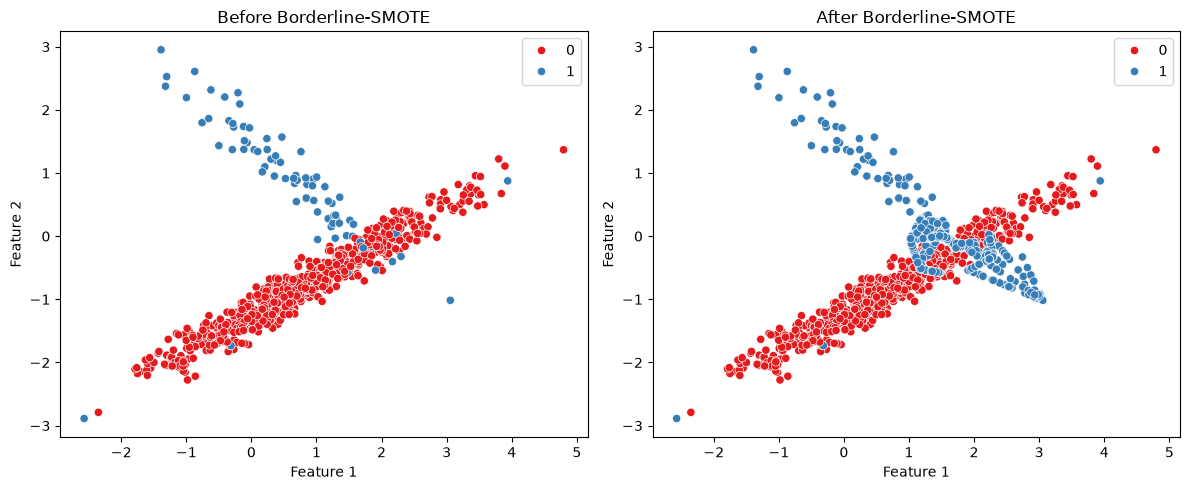

In [11]:

# Borderline-SMOTE - Complete Program

# Step 1: Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import BorderlineSMOTE

# Step 2: Create an Imbalanced Dataset
X, y = make_classification(
    n_samples=1000,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=1,
    weights=[0.90, 0.10],
    class_sep=0.8,
    random_state=42
)

print("Original Dataset Distribution:")
print(Counter(y))

# Step 3: Split Dataset into Training and Testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# Step 4: Apply Borderline-SMOTE
borderline_smote = BorderlineSMOTE(
    sampling_strategy="auto",
    random_state=42,
    kind="borderline-1"
)

X_train_resampled, y_train_resampled = (
    borderline_smote.fit_resample(X_train, y_train)
)

# Step 5: Display Class Distribution
print("\nBefore Borderline-SMOTE:")
print(Counter(y_train))

print("\nAfter Borderline-SMOTE:")
print(Counter(y_train_resampled))

# Step 6: Mathematical Calculation
X_i = 20
X_neighbor = 30
lambda_value = 0.5

X_new = X_i + lambda_value * (X_neighbor - X_i)

print("\nMathematical Calculation:")
print("X_new = X_i + lambda * (X_neighbor - X_i)")
print(f"X_new = {X_i} + {lambda_value} * ({X_neighbor} - {X_i})")
print("X_new =", X_new)

# Step 7: Visualize Before and After Borderline-SMOTE
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.scatterplot(
    x=X_train[:, 0],
    y=X_train[:, 1],
    hue=y_train,
    palette="Set1",
    ax=axes[0]
)

axes[0].set_title("Before Borderline-SMOTE")
axes[0].set_xlabel("Feature 1")
axes[0].set_ylabel("Feature 2")

sns.scatterplot(
    x=X_train_resampled[:, 0],
    y=X_train_resampled[:, 1],
    hue=y_train_resampled,
    palette="Set1",
    ax=axes[1]
)

axes[1].set_title("After Borderline-SMOTE")
axes[1].set_xlabel("Feature 1")
axes[1].set_ylabel("Feature 2")

plt.tight_layout()
plt.show()


Advantages:

1. Focuses on difficult minority-class samples.
2. Helps improve minority-class learning.
3. Can improve fraud detection and rare-event classification.
4. Generates synthetic data instead of simply duplicating records.
5. Can improve recall for the minority class.
   
Disadvantages

1. May generate noisy synthetic samples.
2. Can cause class overlap.
3. May increase overfitting.
4. Requires careful selection of nearest neighbors.
5. Does not guarantee better model performance.

When should we use Borderline-SMOTE?

Use Borderline-SMOTE when:

- The dataset has severe class imbalance.
- Minority-class samples are difficult to classify.
- The decision boundary is important.
- The model has poor minority-class recall.
  
Evaluate the results using:

- Precision
- Recall
- F1-score
- Confusion Matrix
- PR-AUC

In [ ]:
SMOTE vs Borderline-SMOTE:

Feature	                        SMOTE	               Borderline-SMOTE

Main focus	                Minority class	         Borderline minority samples
Sample generation	   Across minority regions	     Near decision boundary
Difficult samples	  Not specifically targeted	     Specifically targeted
Complexity	                    Lower	                Higher
Noise sensitivity	   Can generate noise	          Can emphasize noisy boundaries

### Class Weights

Class Weights is a technique used to handle class imbalance in Machine Learning by assigning different importance (weights) to different classes.

Instead of generating new minority-class samples or removing majority-class samples, Class Weights penalizes the model more when it incorrectly predicts the minority class.

Main objective: Make the Machine Learning model pay more attention to minority-class observations during training.


##### Mathematical Concept

Class Weights can be calculated using the following formula:

$$
W_i = \frac{N}{K \times N_i}
$$

**Where:**

- $W_i$ = Weight assigned to class $i$.
- $N$ = Total number of records.
- $K$ = Total number of classes.
- $N_i$ = Number of records in class $i$.

##### Example

Suppose:

$$
N = 10000
$$

$$
K = 2
$$

$$
N_0 = 9900
$$

$$
N_1 = 100
$$

##### Weight for Normal Transactions

$$
W_0 = \frac{10000}{2 \times 9900}
$$

$$
W_0 = \frac{10000}{19800}
$$

$$
W_0 = 0.5051
$$

##### Weight for Fraud Transactions

$$
W_1 = \frac{10000}{2 \times 100}
$$

$$
W_1 = \frac{10000}{200}
$$

$$
W_1 = 50
$$

##### Final Answer

$$
\boxed{W_0 = 0.5051}
$$

$$
\boxed{W_1 = 50}
$$

The fraud class receives a much higher weight because it has fewer records.

##### Interpretation

- Normal transactions receive a weight of 0.5051.
- Fraud transactions receive a weight of 50.
- The model assigns greater importance to fraud transactions during training.

**Conclusion:** Class Weights helps Machine Learning models pay more attention to minority-class observations without changing the original dataset size.


In [12]:

# Class Weights - Complete Python Program

# Step 1: Import Libraries
import numpy as np
import pandas as pd

from collections import Counter
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix

# Step 2: Create an Imbalanced Dataset
X, y = make_classification(
    n_samples=10000,
    n_features=5,
    n_informative=3,
    n_redundant=1,
    n_classes=2,
    weights=[0.99, 0.01],
    random_state=42
)

print("Original Class Distribution:")
print(Counter(y))

# Step 3: Split the Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# Step 4: Calculate Class Weights
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("\nCalculated Class Weights:")
print(class_weights)

# Step 5: Train Model Without Class Weights
model_without_weights = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model_without_weights.fit(X_train, y_train)

y_pred_without = model_without_weights.predict(X_test)

# Step 6: Train Model With Class Weights
model_with_weights = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

model_with_weights.fit(X_train, y_train)

y_pred_with = model_with_weights.predict(X_test)

# Step 7: Evaluate Model Without Class Weights
print("\nPerformance WITHOUT Class Weights:")

print(confusion_matrix(y_test, y_pred_without))

print(classification_report(
    y_test,
    y_pred_without,
    zero_division=0
))

# Step 8: Evaluate Model With Class Weights
print("\nPerformance WITH Class Weights:")

print(confusion_matrix(y_test, y_pred_with))

print(classification_report(
    y_test,
    y_pred_with,
    zero_division=0
))


Original Class Distribution:
Counter({np.int64(0): 9847, np.int64(1): 153})

Calculated Class Weights:
{np.int64(0): np.float64(0.5077430820005078), np.int64(1): np.float64(32.78688524590164)}

Performance WITHOUT Class Weights:
[[1969    0]
 [  31    0]]
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1969
           1       0.00      0.00      0.00        31

    accuracy                           0.98      2000
   macro avg       0.49      0.50      0.50      2000
weighted avg       0.97      0.98      0.98      2000


Performance WITH Class Weights:
[[1431  538]
 [  13   18]]
              precision    recall  f1-score   support

           0       0.99      0.73      0.84      1969
           1       0.03      0.58      0.06        31

    accuracy                           0.72      2000
   macro avg       0.51      0.65      0.45      2000
weighted avg       0.98      0.72      0.83      2000



Advantages:

1. Handles class imbalance without changing dataset size.
2. Does not generate synthetic samples.
3. Does not remove majority-class observations.
4. Easy to implement in many Machine Learning algorithms.
5. Can improve minority-class recall.
   
Disadvantages:

1. Higher weights may increase false positives.
2. Does not guarantee better model performance.
3. Incorrect weight selection can affect model learning.
4. Some algorithms do not support class weights directly.

### When to use each technique

1.Random Undersampling

Use when:

- The dataset contains a very large number of majority-class records.
- You have enough majority-class examples to remove some records.
- Training time needs to be reduced.
- Removing some majority-class information will not significantly affect model performance.
  
Example: A fraud detection dataset contains 9,900 normal transactions and 100 fraud transactions. You reduce normal transactions to 100.
 
2. Random Oversampling
   
Use when:

- The dataset is small.
- You do not want to remove majority-class records.
- You want to increase minority-class representation.
- You need a simple baseline technique.
  
Example: Duplicate fraud transactions until the minority class has a similar number of records to the majority class.

Best suited for:
 Small datasets where retaining all original records is important.
 
3. SMOTE
   
Use when:

- The dataset has class imbalance.
- The minority class has enough representative examples.
- You want to generate synthetic minority-class samples.
- Simple duplication causes overfitting.
  
Example: Generate new synthetic fraud transaction samples using nearby fraud transactions.

Best suited for
 Imbalanced datasets with continuous numerical features and meaningful minority-class neighborhoods.
 
4. Borderline-SMOTE
   
Use when:

- Minority-class samples are difficult to classify.
- Many minority samples are close to the decision boundary.
- The model struggles to distinguish between majority and minority classes.
  
Example: Fraudulent transactions have patterns similar to normal transactions, making classification difficult.

Best suited for
 Datasets where minority-class samples near the decision boundary are especially important.
 
5. ADASYN
   
Use when:

- Some minority-class observations are more difficult to learn than others.
- You want to generate more synthetic samples in difficult minority-class regions.
- The minority-class distribution is uneven.
  
Example: Generate more synthetic fraud samples around difficult-to-classify fraud transactions.

Best suited for
 Imbalanced datasets with varying levels of minority-class learning difficulty.
 
6.Class Weights

Use when:

- You do not want to modify the dataset.
- You want to penalize minority-class prediction errors more heavily.
- Your Machine Learning algorithm supports class weights.
- You want to retain all original observations.
  
Example: Assign a higher weight to fraudulent transactions than normal transactions during model training.

Best suited for
 Models that support class weighting, such as Logistic Regression, Decision Trees and Random Forest.